# Assignment 3: Build and Evaluate a CNN

## Fashion Lab: how much does convolution help?

I use the **Fashion-MNIST** dataset (70,000 grayscale clothing images, 10 classes) to compare a **small CNN** with a **fully connected network**, and to study the mistakes the CNN makes.

### Tasks
| # | Task | Section |
|---|------|---------|
| 1 | Load and visualize Fashion-MNIST images | Part 1 |
| 2 | Build a small CNN | Part 3 |
| 3 | Compare it with a fully connected baseline | Part 4 |
| 4 | Plot training and validation curves | Part 4 |
| 5 | Explain five misclassified examples | Part 5 |

### My extra: convolution by hand
Before building the CNN, I apply a filter, padding and pooling by hand to one image, to see exactly what a convolution layer does (Part 2).

In [1]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms

torch.manual_seed(42)
np.random.seed(42)

device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch version:", torch.__version__)
print("Using device:", device)

PyTorch version: 2.14.1
Using device: mps


## Part 1: Loading and Visualizing Fashion-MNIST

Each image is a **tensor of shape (1, 28, 28)**: 1 colour channel, 28 rows and 28 columns of pixel values. I normalize the pixels with the dataset's mean (0.2860) and standard deviation (0.3530). The 60,000 training images are split into **54,000 for training** and **6,000 for validation**, and the official **10,000 test images** are kept for the end.

In [3]:
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
MEAN, STD = 0.2860, 0.3530

tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

full_train = datasets.FashionMNIST("data", train=True, download=True, transform=tf)
test_set = datasets.FashionMNIST("data", train=False, download=True, transform=tf)
train_set, val_set = random_split(full_train, [54000, 6000], generator=torch.Generator().manual_seed(42))

BATCH = 128
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH)
test_loader = DataLoader(test_set, batch_size=BATCH)

img, label = full_train[0]
print("one image tensor shape:", tuple(img.shape), "(channels, height, width)")
print("its label:", label, "=", CLASSES[label])
print("pixel range after normalization:", round(img.min().item(), 2), "to", round(img.max().item(), 2))
print("train / val / test:", len(train_set), "/", len(val_set), "/", len(test_set))

xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape))

100.0%
100.0%
100.0%
100.0%

one image tensor shape: (1, 28, 28) (channels, height, width)
its label: 9 = Ankle boot
pixel range after normalization: -0.81 to 2.02
train / val / test: 54000 / 6000 / 10000
one batch: (128, 1, 28, 28) (128,)


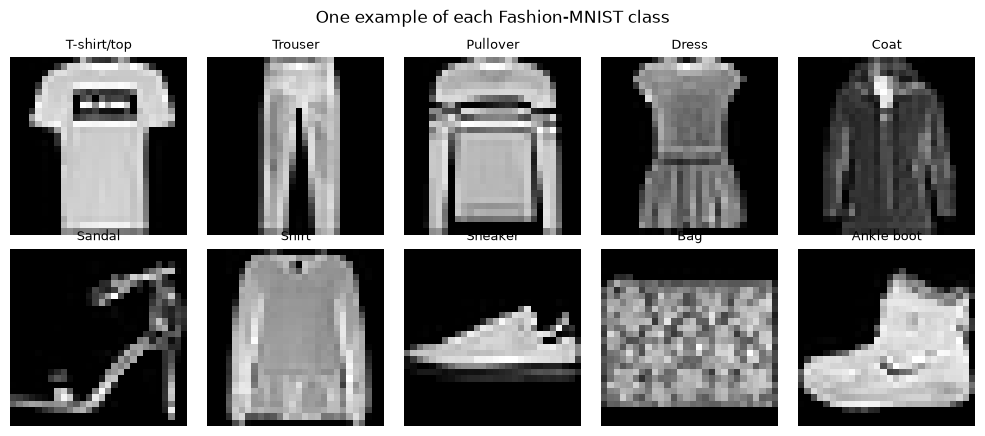

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.4))
targets = full_train.targets
for c, ax in enumerate(axes.flat):
    i = int((targets == c).nonzero()[0])
    ax.imshow(full_train.data[i], cmap="gray")        # raw pixels (0-255) for display
    ax.set_title(CLASSES[c], fontsize=9)
    ax.axis("off")
plt.suptitle("One example of each Fashion-MNIST class")
plt.tight_layout()
plt.show()

In [5]:
raw = full_train.data[0]
print("Raw pixel values (rows 10-17, columns 10-17) of the first image:")
print(raw[10:18, 10:18])
print("\nImages per class:", torch.bincount(full_train.targets).tolist())

Raw pixel values (rows 10-17, columns 10-17) of the first image:
tensor([[  0,   0,   0, 193, 228, 218, 213, 198],
        [  3,   0,  12, 219, 220, 212, 218, 192],
        [  6,   0,  99, 244, 222, 220, 218, 203],
        [  0,   0,  55, 236, 228, 230, 228, 240],
        [  0,   0, 237, 226, 217, 223, 222, 219],
        [145, 204, 228, 207, 213, 221, 218, 208],
        [220, 222, 217, 226, 200, 205, 211, 230],
        [208, 209, 200, 159, 245, 193, 206, 223]], dtype=torch.uint8)

Images per class: [6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000, 6000]


## Part 2: Convolution by Hand

Before building the CNN, I run a convolution **by hand** on one T-shirt image, to see exactly what a convolution layer does:

- a **filter** (3x3 grid of numbers) slides over the image and computes a weighted sum at each position
- **padding** adds a border of zeros so the output keeps its size
- **max pooling** keeps the strongest value in each 2x2 block

I write the sliding loop myself and then check it against PyTorch's own `conv2d`.

In [6]:
import torch.nn.functional as F


def conv2d_manual(image, kernel, padding=0, stride=1):
    """Slide the kernel over the image and sum (patch * kernel) at every position."""
    h, w = image.shape
    k = kernel.shape[0]
    padded = torch.zeros(h + 2 * padding, w + 2 * padding)
    padded[padding:padding + h, padding:padding + w] = image          # zeros around the border
    out_h = (padded.shape[0] - k) // stride + 1
    out_w = (padded.shape[1] - k) // stride + 1
    out = torch.zeros(out_h, out_w)
    for i in range(out_h):
        for j in range(out_w):
            patch = padded[i * stride:i * stride + k, j * stride:j * stride + k]
            out[i, j] = (patch * kernel).sum()
    return out


# a T-shirt image with pixel values scaled to 0-1
idx = int((full_train.targets == 0).nonzero()[0])
shirt = full_train.data[idx].float() / 255

sobel_x = torch.tensor([[-1., 0., 1.], [-2., 0., 2.], [-1., 0., 1.]])    # detects vertical edges
sobel_y = torch.tensor([[-1., -2., -1.], [0., 0., 0.], [1., 2., 1.]])    # detects horizontal edges
blur = torch.ones(3, 3) / 9                                              # smooths the image

vert = conv2d_manual(shirt, sobel_x, padding=1)
horiz = conv2d_manual(shirt, sobel_y, padding=1)
smooth = conv2d_manual(shirt, blur, padding=1)

# check my loop against PyTorch's own convolution
check = F.conv2d(shirt[None, None], sobel_x[None, None], padding=1)[0, 0]
print("max difference from PyTorch's conv2d:", (vert - check).abs().max().item())
print("output shape with padding=1:", tuple(vert.shape))
print("output shape with padding=0:", tuple(conv2d_manual(shirt, sobel_x, padding=0).shape))

max difference from PyTorch's conv2d: 4.76837158203125e-07
output shape with padding=1: (28, 28)
output shape with padding=0: (26, 26)


my max pooling matches PyTorch: True
size after 2x2 max pooling: (14, 14)


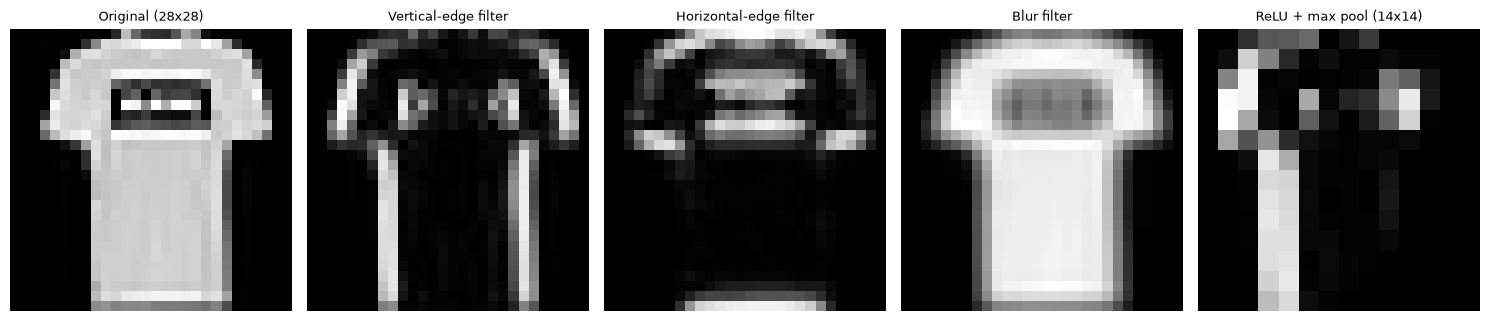

In [7]:
relu_map = F.relu(vert)                                           # keep only positive responses
pooled = F.max_pool2d(relu_map[None, None], 2)[0, 0]              # PyTorch's max pooling
pooled_manual = relu_map.reshape(14, 2, 14, 2).amax(dim=(1, 3))   # my own: max of each 2x2 block

print("my max pooling matches PyTorch:", torch.allclose(pooled, pooled_manual))
print("size after 2x2 max pooling:", tuple(pooled.shape))

panels = [(shirt, "Original (28x28)"),
          (vert.abs(), "Vertical-edge filter"),
          (horiz.abs(), "Horizontal-edge filter"),
          (smooth, "Blur filter"),
          (pooled, "ReLU + max pool (14x14)")]

fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, (pic, title) in zip(axes, panels):
    ax.imshow(pic, cmap="gray")
    ax.set_title(title, fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.savefig("convolution_by_hand.png", dpi=150)
plt.show()

In [8]:
print(f"{'kernel':>7}{'padding':>9}{'stride':>8}{'formula':>9}{'PyTorch':>9}")
for k, p, s in [(3, 0, 1), (3, 1, 1), (5, 0, 1), (5, 2, 1), (3, 1, 2)]:
    formula = (28 - k + 2 * p) // s + 1
    actual = nn.Conv2d(1, 1, kernel_size=k, padding=p, stride=s)(torch.zeros(1, 1, 28, 28)).shape[-1]
    print(f"{k:>7}{p:>9}{s:>8}{formula:>9}{actual:>9}")

 kernel  padding  stride  formula  PyTorch
      3        0       1       26       26
      3        1       1       28       28
      5        0       1       24       24
      5        2       1       28       28
      3        1       2       14       14


In [9]:
layer = nn.Conv2d(in_channels=1, out_channels=8, kernel_size=3, padding=1)

print("filters (weights):", tuple(layer.weight.shape), "= 8 filters, 1 channel, 3x3")
print("biases:", tuple(layer.bias.shape))
print("parameters in this layer:", sum(p.numel() for p in layer.parameters()))

out = layer(shirt[None, None])
print("output shape:", tuple(out.shape), "= 1 image, 8 feature maps, 28x28")

filters (weights): (8, 1, 3, 3) = 8 filters, 1 channel, 3x3
biases: (8,)
parameters in this layer: 80
output shape: (1, 8, 28, 28) = 1 image, 8 feature maps, 28x28


### What I learned from this

- A convolution slides a small **filter** over the image. The **vertical-edge filter** responds where brightness changes from left to right (the sides of the shirt), and the **horizontal-edge filter** responds where it changes from top to bottom (shoulders and hem). The **blur filter** smooths the image.
- **Padding** keeps the output the same size as the input, and without it the output shrinks. The output size follows `(W - K + 2P) / S + 1`, and my formula matched PyTorch in every case.
- **Max pooling** halves the width and height (28x28 to 14x14) by keeping the strongest value of each 2x2 block.
- In a real CNN I do not choose the filter numbers. Each convolution layer holds many filters (for example 8 filters of size 3x3, which is only 80 parameters) that start random and are **learned during training**.

## Part 3: The Models

To make the comparison fair, I build two networks with almost the **same number of parameters** (about 106,000), so any difference in accuracy comes from the **architecture**, not from model size.

**Small CNN:** `Conv(1→16) → ReLU → MaxPool → Conv(16→32) → ReLU → MaxPool → Flatten → Linear(1568→64) → ReLU → Linear(64→10)`

**Fully connected baseline:** `Flatten → Linear(784→124) → ReLU → Linear(124→64) → ReLU → Linear(64→10)`

In [10]:
class SmallCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # 28x28 -> 14x14
            nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),   # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),                       # 32 * 7 * 7 = 1568 numbers
            nn.Linear(32 * 7 * 7, 64), nn.ReLU(),
            nn.Linear(64, 10),                  # 10 clothing classes
        )

    def forward(self, x):
        return self.classifier(self.features(x))


class FullyConnected(nn.Module):
    def __init__(self, hidden=(124, 64)):
        super().__init__()
        layers, prev = [nn.Flatten()], 28 * 28
        for h in hidden:
            layers += [nn.Linear(prev, h), nn.ReLU()]
            prev = h
        layers.append(nn.Linear(prev, 10))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


def count_params(m):
    return sum(p.numel() for p in m.parameters())


print("Small CNN parameters:       ", f"{count_params(SmallCNN()):,}")
print("Fully connected parameters: ", f"{count_params(FullyConnected()):,}")

Small CNN parameters:        105,866
Fully connected parameters:  105,990


In [11]:
trace_model = SmallCNN()
x = torch.zeros(1, 1, 28, 28)
print(f"{'input':<12}-> {tuple(x.shape)}")
for layer in list(trace_model.features) + list(trace_model.classifier):
    x = layer(x)
    print(f"{layer.__class__.__name__:<12}-> {tuple(x.shape)}")

print("\nParameters per layer:")
for name, p in trace_model.named_parameters():
    print(f"  {name:<22}{str(tuple(p.shape)):<18}{p.numel():>8,}")

input       -> (1, 1, 28, 28)
Conv2d      -> (1, 16, 28, 28)
ReLU        -> (1, 16, 28, 28)
MaxPool2d   -> (1, 16, 14, 14)
Conv2d      -> (1, 32, 14, 14)
ReLU        -> (1, 32, 14, 14)
MaxPool2d   -> (1, 32, 7, 7)
Flatten     -> (1, 1568)
Linear      -> (1, 64)
ReLU        -> (1, 64)
Linear      -> (1, 10)

Parameters per layer:
  features.0.weight     (16, 1, 3, 3)          144
  features.0.bias       (16,)                   16
  features.3.weight     (32, 16, 3, 3)       4,608
  features.3.bias       (32,)                   32
  classifier.1.weight   (64, 1568)         100,352
  classifier.1.bias     (64,)                   64
  classifier.3.weight   (10, 64)               640
  classifier.3.bias     (10,)                   10


In [12]:
import copy
import time


def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train() if training else model.eval()
    total_loss, correct, total = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            loss = loss_fn(out, yb)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            total += xb.size(0)

    return total_loss / total, correct / total


def train_model(model, epochs=10, lr=1e-3):
    model = model.to(device)
    loss_fn = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_acc, best_state = 0.0, None
    t0 = time.time()

    for ep in range(1, epochs + 1):
        tl, ta = run_epoch(model, train_loader, loss_fn, optimizer)
        vl, va = run_epoch(model, val_loader, loss_fn)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        if va > best_acc:                                  # keep the best epoch
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"Epoch {ep:2d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}")

    hist["seconds"] = time.time() - t0
    model.load_state_dict(best_state)
    return model, hist


print("Training functions ready")

Training functions ready


In [13]:
print("=== Small CNN ===")
torch.manual_seed(0)
cnn, hist_cnn = train_model(SmallCNN(), epochs=10)

print("\n=== Fully connected baseline ===")
torch.manual_seed(0)
mlp, hist_mlp = train_model(FullyConnected(), epochs=10)

print(f"\nTraining time | CNN {hist_cnn['seconds']:.0f} s | fully connected {hist_mlp['seconds']:.0f} s")

=== Small CNN ===
Epoch  1/10 | train loss 0.5425 acc 0.8083 | val loss 0.3896 acc 0.8623
Epoch  2/10 | train loss 0.3446 acc 0.8766 | val loss 0.3333 acc 0.8812
Epoch  3/10 | train loss 0.3009 acc 0.8922 | val loss 0.3019 acc 0.8925
Epoch  4/10 | train loss 0.2746 acc 0.9017 | val loss 0.2906 acc 0.8970
Epoch  5/10 | train loss 0.2541 acc 0.9086 | val loss 0.2849 acc 0.8987
Epoch  6/10 | train loss 0.2370 acc 0.9146 | val loss 0.2720 acc 0.9012
Epoch  7/10 | train loss 0.2243 acc 0.9190 | val loss 0.2770 acc 0.8962
Epoch  8/10 | train loss 0.2098 acc 0.9235 | val loss 0.2731 acc 0.8992
Epoch  9/10 | train loss 0.1985 acc 0.9276 | val loss 0.2519 acc 0.9058
Epoch 10/10 | train loss 0.1860 acc 0.9321 | val loss 0.2542 acc 0.9062

=== Fully connected baseline ===
Epoch  1/10 | train loss 0.5305 acc 0.8113 | val loss 0.4182 acc 0.8502
Epoch  2/10 | train loss 0.3759 acc 0.8626 | val loss 0.3681 acc 0.8663
Epoch  3/10 | train loss 0.3349 acc 0.8748 | val loss 0.3468 acc 0.8712
Epoch  4/10 

## Part 4: Training Curves, Comparison and Test Results

I plot the **training and validation curves** of both models, compare them in a **table**, and then evaluate both once on the **10,000 test images**, which were never used for training or for choosing the best epoch. I also look at accuracy **per clothing class**.

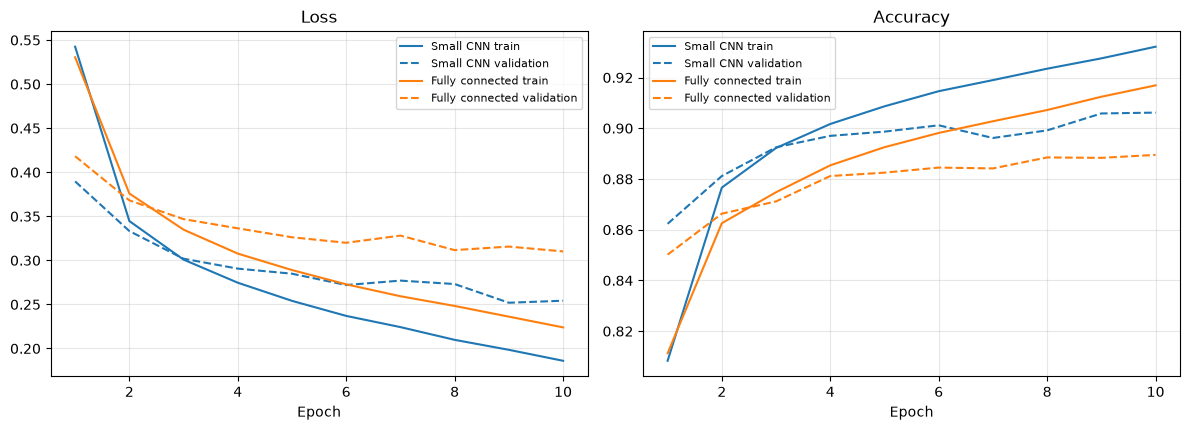

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ep = range(1, len(hist_cnn["train_loss"]) + 1)

for model_name, h, color in [("Small CNN", hist_cnn, "tab:blue"), ("Fully connected", hist_mlp, "tab:orange")]:
    ax[0].plot(ep, h["train_loss"], color=color, label=f"{model_name} train")
    ax[0].plot(ep, h["val_loss"], color=color, linestyle="--", label=f"{model_name} validation")
    ax[1].plot(ep, h["train_acc"], color=color, label=f"{model_name} train")
    ax[1].plot(ep, h["val_acc"], color=color, linestyle="--", label=f"{model_name} validation")

ax[0].set_title("Loss")
ax[1].set_title("Accuracy")
for a in ax:
    a.set_xlabel("Epoch")
    a.grid(alpha=0.3)
    a.legend(fontsize=8)

plt.tight_layout()
plt.savefig("training_curves_comparison.png", dpi=150)
plt.show()

In [15]:
import csv


@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    probs, labels, images = [], [], []
    for xb, yb in loader:
        out = model(xb.to(device))
        probs.append(torch.softmax(out, dim=1).cpu())
        labels.append(yb)
        images.append(xb)
    return torch.cat(probs), torch.cat(labels), torch.cat(images)


cnn_probs, test_labels, test_images = predict_all(cnn, test_loader)
mlp_probs, _, _ = predict_all(mlp, test_loader)
cnn_pred, mlp_pred = cnn_probs.argmax(1), mlp_probs.argmax(1)

table = []
for name, model, h, pred in [("Small CNN", cnn, hist_cnn, cnn_pred), ("Fully connected", mlp, hist_mlp, mlp_pred)]:
    best_ep = int(np.argmax(h["val_acc"]))                    # the epoch we kept
    table.append({
        "model": name,
        "params": count_params(model),
        "seconds": h["seconds"],
        "train_acc": h["train_acc"][best_ep],
        "val_acc": h["val_acc"][best_ep],
        "test_acc": (pred == test_labels).float().mean().item(),
        "best_epoch": best_ep + 1,
    })

print(f"{'model':<18}{'params':>10}{'time (s)':>10}{'best ep':>9}{'train':>8}{'val':>8}{'test':>8}{'gap':>8}")
for r in table:
    print(f"{r['model']:<18}{r['params']:>10,}{r['seconds']:>10.0f}{r['best_epoch']:>9}"
          f"{r['train_acc']:>8.4f}{r['val_acc']:>8.4f}{r['test_acc']:>8.4f}{r['train_acc'] - r['val_acc']:>8.4f}")

with open("comparison_table.csv", "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["model", "params", "train_seconds", "best_epoch", "train_acc", "val_acc", "test_acc"])
    for r in table:
        w.writerow([r["model"], r["params"], round(r["seconds"]), r["best_epoch"],
                    round(r["train_acc"], 4), round(r["val_acc"], 4), round(r["test_acc"], 4)])

print("\nWrong test predictions | CNN:", int((cnn_pred != test_labels).sum()),
      "| fully connected:", int((mlp_pred != test_labels).sum()), "(out of 10,000)")
print("Saved comparison_table.csv")

model                 params  time (s)  best ep   train     val    test     gap
Small CNN            105,866       108       10  0.9321  0.9062  0.9056  0.0260
Fully connected      105,990        50       10  0.9169  0.8895  0.8824  0.0274

Wrong test predictions | CNN: 944 | fully connected: 1176 (out of 10,000)
Saved comparison_table.csv


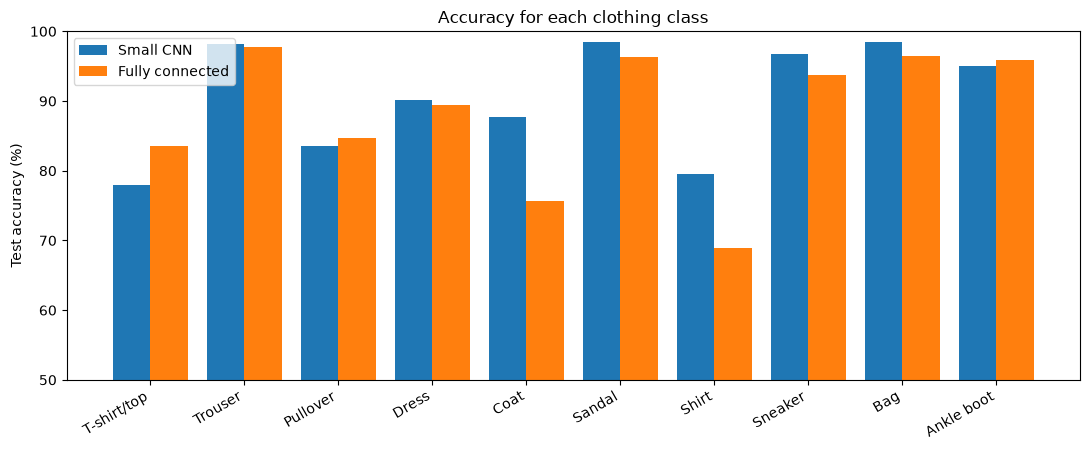

Hardest classes for the CNN: T-shirt/top (77.9%), Shirt (79.5%), Pullover (83.5%)
Easiest classes for the CNN: Bag (98.5%), Sandal (98.5%), Trouser (98.2%)


In [16]:
per_class = {}
for name, pred in [("Small CNN", cnn_pred), ("Fully connected", mlp_pred)]:
    per_class[name] = [(pred[test_labels == c] == c).float().mean().item() for c in range(10)]

x = np.arange(10)
plt.figure(figsize=(11, 4.6))
plt.bar(x - 0.2, [a * 100 for a in per_class["Small CNN"]], width=0.4, label="Small CNN")
plt.bar(x + 0.2, [a * 100 for a in per_class["Fully connected"]], width=0.4, label="Fully connected")
plt.xticks(x, CLASSES, rotation=30, ha="right")
plt.ylabel("Test accuracy (%)")
plt.ylim(50, 100)
plt.title("Accuracy for each clothing class")
plt.legend()
plt.tight_layout()
plt.savefig("per_class_accuracy.png", dpi=150)
plt.show()

order = np.argsort(per_class["Small CNN"])
print("Hardest classes for the CNN:", ", ".join(f"{CLASSES[c]} ({per_class['Small CNN'][c] * 100:.1f}%)" for c in order[:3]))
print("Easiest classes for the CNN:", ", ".join(f"{CLASSES[c]} ({per_class['Small CNN'][c] * 100:.1f}%)" for c in order[::-1][:3]))

In [17]:
from IPython.display import Markdown, display

c, m = table
n_cnn = int((cnn_pred != test_labels).sum())
n_mlp = int((mlp_pred != test_labels).sum())
diff = (c["test_acc"] - m["test_acc"]) * 100
fewer = (1 - n_cnn / n_mlp) * 100
winner = "small CNN" if c["test_acc"] > m["test_acc"] else "fully connected network"
hard = ", ".join(CLASSES[k] for k in order[:3])
easy = ", ".join(CLASSES[k] for k in order[::-1][:3])

text = f"""
### What the results show (numbers computed from my own results)

- **Same size, different result:** the CNN has {c['params']:,} parameters and the fully connected network {m['params']:,}, almost equal. The **{winner}** wins on the test set: **{c['test_acc'] * 100:.2f}%** for the CNN against **{m['test_acc'] * 100:.2f}%** for the fully connected network, a difference of **{abs(diff):.2f} points**.
- **Fewer mistakes:** the CNN made {n_cnn} wrong predictions and the fully connected network {n_mlp} out of 10,000 ({abs(fewer):.0f}% {'fewer' if fewer > 0 else 'more'} for the CNN).
- **Generalization:** validation and test accuracy are close for both models (CNN {c['val_acc'] * 100:.2f}% vs {c['test_acc'] * 100:.2f}%, fully connected {m['val_acc'] * 100:.2f}% vs {m['test_acc'] * 100:.2f}%), so choosing the best epoch on validation data held up on unseen data.
- **Overfitting signs:** the train-validation accuracy gap is {(c['train_acc'] - c['val_acc']) * 100:.1f} points for the CNN and {(m['train_acc'] - m['val_acc']) * 100:.1f} points for the fully connected network. Training accuracy keeps rising after validation flattens, so both models start to memorize the training images.
- **Easy and hard classes:** the CNN is best on **{easy}** and weakest on **{hard}**. Garments with similar outlines (shirts, T-shirts, pullovers, coats) are the ones confused with each other.
- **Cost:** the CNN took {c['seconds']:.0f} s to train and the fully connected network {m['seconds']:.0f} s. Convolutions reuse the same small filters across the whole image, so they get more out of the same number of parameters, but each step costs more computation.
"""
display(Markdown(text))


### What the results show (numbers computed from my own results)

- **Same size, different result:** the CNN has 105,866 parameters and the fully connected network 105,990, almost equal. The **small CNN** wins on the test set: **90.56%** for the CNN against **88.24%** for the fully connected network, a difference of **2.32 points**.
- **Fewer mistakes:** the CNN made 944 wrong predictions and the fully connected network 1176 out of 10,000 (20% fewer for the CNN).
- **Generalization:** validation and test accuracy are close for both models (CNN 90.62% vs 90.56%, fully connected 88.95% vs 88.24%), so choosing the best epoch on validation data held up on unseen data.
- **Overfitting signs:** the train-validation accuracy gap is 2.6 points for the CNN and 2.7 points for the fully connected network. Training accuracy keeps rising after validation flattens, so both models start to memorize the training images.
- **Easy and hard classes:** the CNN is best on **Bag, Sandal, Trouser** and weakest on **T-shirt/top, Shirt, Pullover**. Garments with similar outlines (shirts, T-shirts, pullovers, coats) are the ones confused with each other.
- **Cost:** the CNN took 108 s to train and the fully connected network 50 s. Convolutions reuse the same small filters across the whole image, so they get more out of the same number of parameters, but each step costs more computation.


## Part 5: Explaining Five Misclassified Examples

First I look at the CNN's **confusion matrix** to find which clothing classes it mixes up most often. Then I take the **five most common mistakes**, and for each one I show the CNN's **most confident wrong prediction** together with the model's top 3 probabilities. I also check whether the fully connected network got the same image wrong.

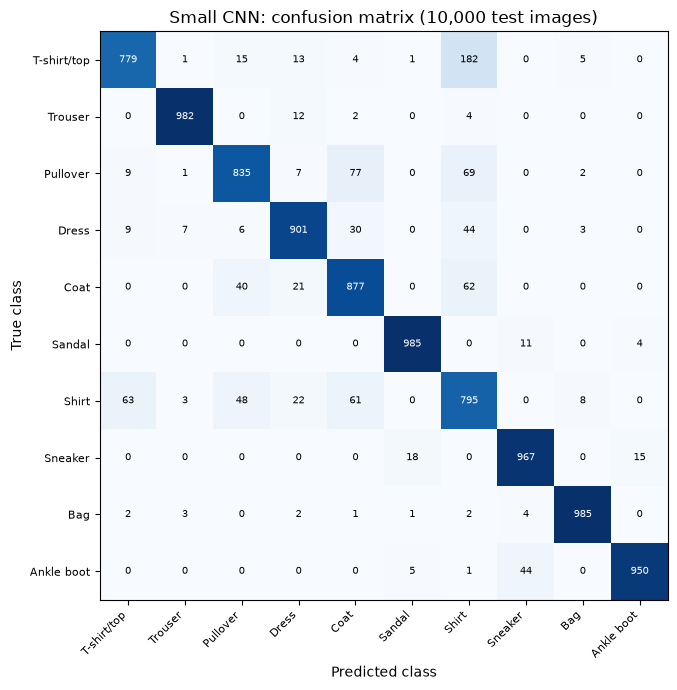

Most common mistakes (true class -> predicted class):
  T-shirt/top  -> Shirt         182 times
  Pullover     -> Coat           77 times
  Pullover     -> Shirt          69 times
  Shirt        -> T-shirt/top    63 times
  Coat         -> Shirt          62 times
  Shirt        -> Coat           61 times
  Shirt        -> Pullover       48 times
  Ankle boot   -> Sneaker        44 times


In [18]:
cm = torch.bincount(test_labels * 10 + cnn_pred, minlength=100).reshape(10, 10)

fig, ax = plt.subplots(figsize=(8.5, 7))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10), CLASSES, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(10), CLASSES, fontsize=8)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Small CNN: confusion matrix (10,000 test images)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center", fontsize=7,
                color="white" if cm[i, j] > cm.max() * 0.5 else "black")
plt.tight_layout()
plt.savefig("cnn_confusion_matrix.png", dpi=150)
plt.show()

top_pairs = sorted([(int(cm[t, p]), t, p) for t in range(10) for p in range(10) if t != p], reverse=True)
print("Most common mistakes (true class -> predicted class):")
for count, t, p in top_pairs[:8]:
    print(f"  {CLASSES[t]:<12} -> {CLASSES[p]:<12} {count:>4} times")

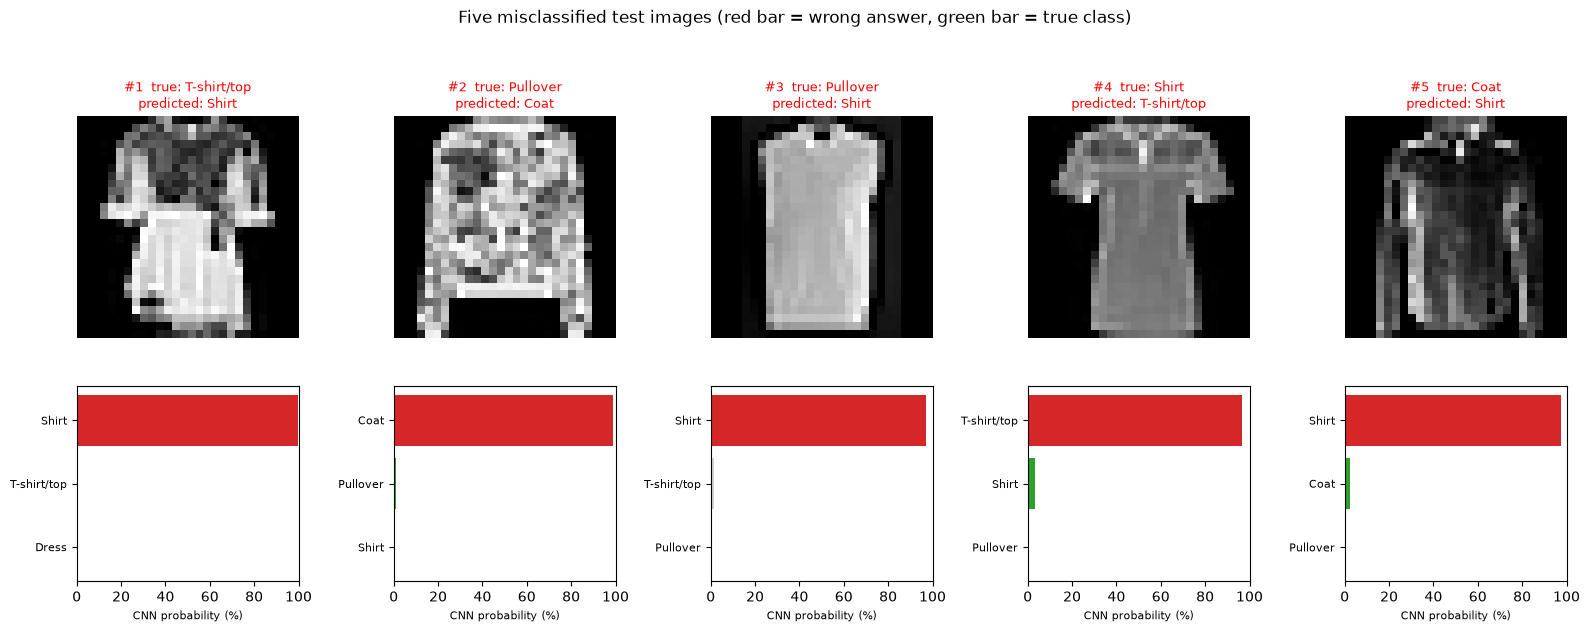

In [19]:
chosen = []
for count, t, p in top_pairs[:5]:
    idx = ((test_labels == t) & (cnn_pred == p)).nonzero().flatten()
    best = idx[cnn_probs[idx, p].argmax()].item()          # the most confident wrong prediction
    chosen.append((best, t, p, count))

fig, axes = plt.subplots(2, 5, figsize=(16, 6.4), gridspec_kw={"height_ratios": [3, 1.6]})
for col, (i, t, p, count) in enumerate(chosen):
    ax = axes[0, col]
    ax.imshow(test_images[i].squeeze() * STD + MEAN, cmap="gray")
    ax.set_title(f"#{col + 1}  true: {CLASSES[t]}\npredicted: {CLASSES[p]}", fontsize=9, color="red")
    ax.axis("off")

    top = cnn_probs[i].topk(3)
    top_idx = top.indices.tolist()[::-1]
    top_val = (top.values.numpy() * 100)[::-1]
    colors = ["tab:red" if k == p else "tab:green" if k == t else "lightgray" for k in top_idx]
    bx = axes[1, col]
    bx.barh(range(3), top_val, color=colors)
    bx.set_yticks(range(3), [CLASSES[k] for k in top_idx], fontsize=8)
    bx.set_xlim(0, 100)
    bx.set_xlabel("CNN probability (%)", fontsize=8)

plt.suptitle("Five misclassified test images (red bar = wrong answer, green bar = true class)")
plt.tight_layout()
plt.savefig("misclassified_examples.png", dpi=150)
plt.show()

In [20]:
print(f"{'#':<3}{'true class':<13}{'predicted':<13}{'confidence':>11}{'P(true)':>9}{'fully connected says':>24}{'this mistake':>14}")
for n, (i, t, p, count) in enumerate(chosen, 1):
    mlp_says = CLASSES[int(mlp_pred[i])] + (" (right)" if int(mlp_pred[i]) == t else " (wrong)")
    print(f"{n:<3}{CLASSES[t]:<13}{CLASSES[p]:<13}{cnn_probs[i, p].item() * 100:>10.0f}%"
          f"{cnn_probs[i, t].item() * 100:>8.0f}%{mlp_says:>24}{count:>10} times")

#  true class   predicted     confidence  P(true)    fully connected says  this mistake
1  T-shirt/top  Shirt               100%       0%           Shirt (wrong)       182 times
2  Pullover     Coat                 99%       1%        Pullover (right)        77 times
3  Pullover     Shirt                97%       1%           Shirt (wrong)        69 times
4  Shirt        T-shirt/top          97%       3%     T-shirt/top (wrong)        63 times
5  Coat         Shirt                97%       2%           Shirt (wrong)        62 times


In [21]:
from IPython.display import Markdown, display

reasons = {
    frozenset({"Shirt", "T-shirt/top"}): "Both have a similar body outline. They differ mostly in small details (collar, buttons, sleeve length) that almost disappear at 28x28 pixels.",
    frozenset({"Shirt", "Pullover"}): "Both are long-sleeved tops with a similar outline, and the buttons or collar of a shirt are only a few pixels wide.",
    frozenset({"Shirt", "Coat"}): "Both are long-sleeved garments with a similar silhouette, and a coat's zip or buttons are faint in such a small image.",
    frozenset({"Pullover", "Coat"}): "Both are long-sleeved, roughly rectangular garments. The features that separate them (zip, collar, length) are small and often low contrast.",
    frozenset({"T-shirt/top", "Pullover"}): "Both are upper-body garments with a similar shape, and the main difference is the sleeve length.",
    frozenset({"T-shirt/top", "Dress"}): "A short dress and a long top both form a narrow vertical shape, and the cues that separate them are small.",
    frozenset({"Dress", "Coat"}): "Both are long, narrow garments, and a coat's details are faint at this resolution.",
    frozenset({"Sandal", "Sneaker"}): "Both are low footwear with a similar overall outline, and a sandal's open straps can look like a sneaker's texture at low resolution.",
    frozenset({"Sandal", "Ankle boot"}): "Both are footwear with a similar sole shape, and the open straps of a sandal are thin details.",
    frozenset({"Sneaker", "Ankle boot"}): "Both are closed shoes with a similar sole. The height of the ankle part is the main difference.",
}
default_reason = "The two classes have a similar overall shape, so the small details that separate them are hard to see at 28x28 pixels."

lines = []
for n, (i, t, p, count) in enumerate(chosen, 1):
    conf = cnn_probs[i, p].item() * 100
    p_true = cnn_probs[i, t].item() * 100
    why = reasons.get(frozenset({CLASSES[t], CLASSES[p]}), default_reason)
    if int(mlp_pred[i]) == t:
        agree = "The fully connected network classified this image correctly, so here the CNN was the weaker model."
    else:
        agree = "The fully connected network also got this image wrong, which suggests the image itself is ambiguous."
    lines.append(f"{n}. **{CLASSES[t]} predicted as {CLASSES[p]}.** The CNN was {conf:.0f}% sure of its answer and gave only "
                 f"{p_true:.0f}% to the true class. It made this confusion {count} times on the test set. {why} {agree}")

display(Markdown("### Explanation of the five mistakes\n\n" + "\n\n".join(lines)))

### Explanation of the five mistakes

1. **T-shirt/top predicted as Shirt.** The CNN was 100% sure of its answer and gave only 0% to the true class. It made this confusion 182 times on the test set. Both have a similar body outline. They differ mostly in small details (collar, buttons, sleeve length) that almost disappear at 28x28 pixels. The fully connected network also got this image wrong, which suggests the image itself is ambiguous.

2. **Pullover predicted as Coat.** The CNN was 99% sure of its answer and gave only 1% to the true class. It made this confusion 77 times on the test set. Both are long-sleeved, roughly rectangular garments. The features that separate them (zip, collar, length) are small and often low contrast. The fully connected network classified this image correctly, so here the CNN was the weaker model.

3. **Pullover predicted as Shirt.** The CNN was 97% sure of its answer and gave only 1% to the true class. It made this confusion 69 times on the test set. Both are long-sleeved tops with a similar outline, and the buttons or collar of a shirt are only a few pixels wide. The fully connected network also got this image wrong, which suggests the image itself is ambiguous.

4. **Shirt predicted as T-shirt/top.** The CNN was 97% sure of its answer and gave only 3% to the true class. It made this confusion 63 times on the test set. Both have a similar body outline. They differ mostly in small details (collar, buttons, sleeve length) that almost disappear at 28x28 pixels. The fully connected network also got this image wrong, which suggests the image itself is ambiguous.

5. **Coat predicted as Shirt.** The CNN was 97% sure of its answer and gave only 2% to the true class. It made this confusion 62 times on the test set. Both are long-sleeved garments with a similar silhouette, and a coat's zip or buttons are faint in such a small image. The fully connected network also got this image wrong, which suggests the image itself is ambiguous.

### Common reasons for these mistakes

- **Similar shapes:** the confused pairs are items with a similar outline (tops and coats, or low shoes). The CNN mostly works with shapes, so items with the same silhouette are hard to separate.
- **Low resolution:** at 28x28 pixels, details such as buttons, collars, zips and straps are only a pixel or two wide.
- **Confidence is not correctness:** the CNN was often quite sure of a wrong answer, so a high probability does not prove it is right.
- **Ambiguous images:** when both models fail on the same image, the image itself is hard, and some of these items are hard even for a person.

In [22]:
from IPython.display import Markdown, display

pairs_text = ", ".join(f"{CLASSES[t]} read as {CLASSES[p]} ({count} times)" for count, t, p in top_pairs[:3])

conclusion = f"""
## Part 6: Conclusion

- **CNN vs fully connected:** with almost the same number of parameters ({c['params']:,} and {m['params']:,}), the **{winner}** scored higher on the test set: **{c['test_acc'] * 100:.2f}%** for the CNN against **{m['test_acc'] * 100:.2f}%** for the fully connected network.
- **Why:** a fully connected network flattens the image, so it does not know which pixels are neighbours. A CNN slides the same small filters over the whole image, so it finds edges and shapes wherever they appear and needs fewer parameters to do it.
- **Training behaviour:** training accuracy keeps rising after validation accuracy flattens, so both models start to memorize the training set. I kept the model from the epoch with the best validation accuracy.
- **Where it fails:** the most frequent mistakes are {pairs_text}. These are garments with similar outlines, and at 28x28 pixels the details that separate them (collars, buttons, zips) are only a pixel or two wide.
- **Best and worst classes:** best on {easy}, weakest on {hard}.
- **What I did by hand:** I wrote the convolution loop myself and checked it against PyTorch, which showed how filters, padding and pooling change the size and content of an image.
"""
display(Markdown(conclusion))


## Part 6: Conclusion

- **CNN vs fully connected:** with almost the same number of parameters (105,866 and 105,990), the **small CNN** scored higher on the test set: **90.56%** for the CNN against **88.24%** for the fully connected network.
- **Why:** a fully connected network flattens the image, so it does not know which pixels are neighbours. A CNN slides the same small filters over the whole image, so it finds edges and shapes wherever they appear and needs fewer parameters to do it.
- **Training behaviour:** training accuracy keeps rising after validation accuracy flattens, so both models start to memorize the training set. I kept the model from the epoch with the best validation accuracy.
- **Where it fails:** the most frequent mistakes are T-shirt/top read as Shirt (182 times), Pullover read as Coat (77 times), Pullover read as Shirt (69 times). These are garments with similar outlines, and at 28x28 pixels the details that separate them (collars, buttons, zips) are only a pixel or two wide.
- **Best and worst classes:** best on Bag, Sandal, Trouser, weakest on T-shirt/top, Shirt, Pullover.
- **What I did by hand:** I wrote the convolution loop myself and checked it against PyTorch, which showed how filters, padding and pooling change the size and content of an image.


### Task checklist

| Task | Where |
|------|-------|
| 1. Load and visualize Fashion-MNIST images | Part 1 |
| 2. Build a small CNN | Part 3 |
| 3. Compare it with a fully connected baseline | Parts 3-4 (and `comparison_table.csv`) |
| 4. Plot training and validation curves | Part 4 |
| 5. Explain five misclassified examples | Part 5 |
| Extra: convolution by hand | Part 2 |